In [1]:
import pandas as pd
import numpy as np
import lifelines 
import sksurv as sks
import matplotlib.pyplot as plt
from bart_survival import surv_bart as sb


import lifelines as ll
from lifelines import KaplanMeierFitter
import subprocess
import threading as th
import multiprocessing as mp
import sys
sys.path.append("../src/")
import sim_adj as sm
import arviz as az
# import brt_adj as sb

import pymc as pm 
import pymc_bart as pb
import random



In [2]:
def reindex(e):
    q, z = np.unique(e, return_index=True)
    
    for i,v in enumerate(e):
        # print(i)
        # indx = np.where(q == i)
        indx = q.tolist().index(v)
        # print(indx)
        e[i]= indx
    return e

In [3]:
def get_quant_events(qnt_t, event):
	q = np.array(qnt_t)
	et_ = event["t_event"].copy()
	et_out = event["t_event"].copy()
	es_out = event["status"].copy()
	for i in range(q.shape[0]):
		if i == 0:
			msk = et_<=q[i]
			et_out[msk] = q[i]
			# print(np.unique(et_out))
		else:
			msk = (q[i-1] < et_) & (et_ <= q[i])
			et_out[msk] = q[i]
			# print(np.unique(et_out))
			if i == q.shape[0]-1:
				msk = et_ > q[i]
				et_out[msk] = q[i]
				es_out[msk] = 0

	return {"t_event":et_out, "status":es_out}

def cox_ph_3_2(x_mat, event_dict, times, test):
    cph = lifelines.CoxPHFitter()
    q = np.hstack([event_dict["t_event"].reshape(-1,1),event_dict["status"].reshape(-1,1),x_mat]) 
    col = ["T", "E"] + [f"x_{i}" for i in range(x_mat.shape[1])] 
    q = pd.DataFrame(q, columns=col)

    cph.fit(q , "T", "E")
    cph_sv = cph.predict_survival_function(x_mat, times=times).to_numpy().T
    cph_sv_test = cph.predict_survival_function(test, times=times).to_numpy().T
    return cph_sv, cph_sv_test

def get_py_bart_surv3_2(x_mat, event_dict, model_dict, sampler_dict, test):
    # event_dict["t_event"] = reindex(event_dict["t_event"])
    # print(event_dict["t_event"])
    # return
    trn = sb.get_surv_pre_train(y_time = event_dict["t_event"], y_status=event_dict["status"], x = x_mat, weight=None)
    post_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=x_mat)
    # y2 = trn["y"].flatten()
    # y2[y2==0] = -1

    BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)
    # trn["w"][trn["x"][:,0]== trn["x"][:,0].max()] = 10
    # print(trn["x"][:,0].max())
    # return 1
    # BSM.offset = -1
    BSM.fit(y=trn["y"], X=trn["x"], weights=trn["w"], coords = trn["coord"], random_seed=99)
    # post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])
    post1 = BSM.bart_predict(X_pred=post_test["post_x"], coords=post_test["coords"], size=2000)
    sv_prob = sb.get_sv_prob(post1)
    # uniq_t = BSM.uniq_times

    # do test
    # post_test_test = sb.get_posterior_test(y_sk = , x_test = test) # old
    post_test_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=test)
    # post_test = BSM.sample_posterior_predictive(X_pred=post_test_test["post_x"], coords=post_test_test["coords"])
    post_test = BSM.bart_predict(X_pred=post_test_test["post_x"], coords=post_test_test["coords"], size=2000)
    sv_prob_test = sb.get_sv_prob(post_test)

    
    del BSM
    childs = mp.active_children()
    for child in childs:
        child.kill()
    # return sv_prob, sv_prob_test
    return sv_prob, sv_prob_test

# np.arange(11)
def save_to_csv(event_dict, x_mat, file="exp1_tmp.csv"):
    """helper function that passes the simulated event dataset to a csv
    - Used for R-bart

    Args:
        event_dict (_type_): _description_
        x_mat (_type_): _description_
        file (str, optional): _description_. Defaults to "exp1_tmp.csv".
    """
    col = ["t","s"] + ["x"+str(i) for i in range(x_mat.shape[1])]
    df = pd.DataFrame(np.hstack(
        [
            event_dict["t_event"],
            event_dict["status"],
            x_mat
        ]
    ),columns= col)
    exp_name = file
    path = f"../data/{exp_name}"
    with open(path, 'w') as f:
        df.to_csv(f, index=False)
    # df.to_csv(path,index = False)

def get_r_bart3_2(event_dict, x_mat, x_mat_tst, event_dict_tst):
    save_to_csv(event_dict, x_mat, file="exp3_tmp.csv")
    save_to_csv(event_dict_tst, x_mat_tst, file="exp3_tmp_tst.csv")
    
    subprocess.call("/usr/local/bin/Rscript --vanilla ../R/bart_3.R", shell=True)
    # with open("../data/exp3_tmp_out3.csv","r") as f:
        # r_sv = pd.read_csv(f).values
    r_sv = pd.read_csv("../data/exp3_tmp_out3_mu.csv").values
    r_sv_l = pd.read_csv("../data/exp3_tmp_out3_cil.csv").values
    r_sv_h = pd.read_csv("../data/exp3_tmp_out3_cih.csv").values

    r_sv_t = pd.read_csv("../data/exp3_tmp_out3_mu_t.csv").values
    r_sv_l_t = pd.read_csv("../data/exp3_tmp_out3_cil_t.csv").values
    r_sv_h_t = pd.read_csv("../data/exp3_tmp_out3_cih_t.csv").values

    return r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t

def rsqr(true, est):
    SSR = np.sum(np.power(true - est, 2))
    SST = np.sum(np.power(true - np.mean(true), 2))
    return 1-(SSR/SST)

def medabs(true, est):
    mab = np.median(np.abs(true-est))
    return mab

def rmse(true, est):
    # true = check_array(true)
    # est = check_array(est)
    out = np.sqrt(np.power((true - est),2).mean(0))
    return out

def bias(true, est):
    # true = check_array(true)
    # est = check_array(est)
    out = (true-est).mean(0)
    return out


In [4]:

# comp 3
SPLIT_RULES3 =  [
    "pmb.ContinuousSplitRule()", # time
    "pmb.ContinuousSplitRule()", 
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()"
]
MODEL_DICT3 = {"trees": 100,
	"split_rules": SPLIT_RULES3
}

SAMPLER_DICT3 = { # new
	"draws": 200,
	"tune": 50,
	"cores": 12,
	"chains": 12,
	"compute_convergence_checks": False
}

EXP_NAME = "cmplx_new"
RUN_NAME = "cmplx_1_400_200_2_test"
RUN_NAME_cmplx3 = "cmplx_3_400"

###########################
# ITERATIONS
ITERS = 200
SEED_ADDL=99
N = [400]
N_cmplx3 = [400, 1000, 4000]
ITERS_cmplx3 = 3
PLOT_ALL=True

# complex_3 = {
#     "type": "Complex, continuous, 20% cens",
#     "x_vars": 10, 
#     "VAR_CLASS": [1,1,1,1,1,1,1,1,1,1],
#     # "VAR_CLASS": [2,2,2,2,2,2,2,2,2,2],
#     "VAR_PROB":[None,None,None,None,None,None,None,None,None,None],
#     # "VAR_PROB":[.5,.5,.5,.5,.5,.5,.5,.5,.5,.5],
#     "scale_f" : "np.exp(3 + 0.5*np.sin(np.pi * x_mat[:,0] * x_mat[:,1]) + np.power((x_mat[:,2]-0.5), 2) + 0.5* x_mat[:,3] + 0.25 * x_mat[:,4])",
#     # "scale_f": "20 + 5*(x_mat[:,0] + x_mat[:,1] + x_mat[:,2] + x_mat[:,3] + x_mat[:,4] + x_mat[:,5] + 10*x_mat[:,6])",
#     "shape_f": "2",
#     "cens_scale":3.7
# }

In [5]:

def get_sim(rng, N, type, x_vars, VAR_CLASS, VAR_PROB, scale_f, shape_f, cens_scale):
    """Generates simulation dataest

    Args:
        rng (_type_): if int, generate new rng seeded as int value.
        N (_type_): _description_
        type (_type_): _description_
        x_vars (_type_): _description_
        VAR_CLASS (_type_): _description_
        VAR_PROB (_type_): _description_
        scale_f (_type_): _description_
        shape_f (_type_): _description_
        cens_scale (_type_): _description_

    Returns:
        _type_: _description_
    """
    x_mat = sm.get_x_matrix(
        N = N,
        x_vars = x_vars, 
        VAR_CLASS=VAR_CLASS,
        VAR_PROB= VAR_PROB,
        rng = rng
    )

    event_dict, sv_true, sv_scale_true = sm.simulate_survival(
        x_mat = x_mat,
        scale_f=scale_f,
        shape_f=shape_f,
        cens_scale=cens_scale,
        rng = rng,
        eos = 100
    )
    return type, x_mat, event_dict, sv_true, sv_scale_true



mean shape 2.254314428642857
mean scale 91.09970562857143
507.0
mean time draws 84.63129001957789
cens mean 232.81714285714287


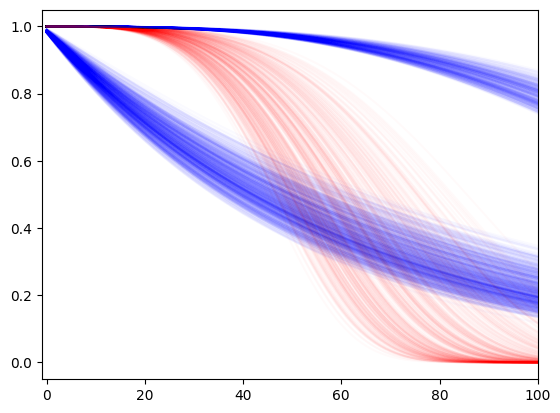

In [6]:
complex_3 = {
    "type": "Complex, continuous, 20% cens",
    "x_vars": 10, 
    # "VAR_CLASS": [1,1,1,1,1,1,1,1,1,1],
    "VAR_CLASS": [2,2,1,1,1,1,1,1,1,1],
    # "VAR_PROB":[None,None,None,None,None,None,None,None,None,None],
    "VAR_PROB":[.5,.5,None,None,None,None,None,None,None,None],
    # "scale_f" : "np.exp(3 + 0.5*np.sin(np.pi * x_mat[:,0] * x_mat[:,1]) + np.power((x_mat[:,2]-0.5), 2) + 0.5* x_mat[:,3] + 0.25 * x_mat[:,4])",
    # "scale_f": "20 + 5*(x_mat[:,0] + x_mat[:,1] + x_mat[:,2] + x_mat[:,3] + x_mat[:,4] + x_mat[:,5] + 10*x_mat[:,6])",
    "scale_f": "50 + \
        100*x_mat[:,0] -\
        100*x_mat[:,1]*x_mat[:,0]+ \
        10*x_mat[:,2] + \
        20*np.power(x_mat[:,3],2) + \
        20 * x_mat[:,3] * x_mat[:,4]",
        # 5*x_mat[:,3] +\
        # 10*np.sin(x_mat[:,2]*x_mat[:,0]*x_mat[:,1]) +\
        # 25*x_mat[:,4]* x_mat[:,0] - 25*x_mat[:,4]*x_mat[:,1]*x_mat[:,0]",
        # 10 * x_mat[:,3] + 0 * x_mat[:,3]*x_mat[:,0]*x_mat[:,1]",
    "shape_f": "1 + \
        2*x_mat[:,0] + \
        1*x_mat[:,1]*x_mat[:,0] + \
        .1*x_mat[:,1]*np.power(x_mat[:,4],2)", #
        # .5*x_mat[:,2]*x_mat[:,0] * x_mat[:,1] +\
        # .5 * x_mat[:,4]*x_mat[:,0] - .5 *x_mat[:,4]*x_mat[:,0]*x_mat[:,1] +\
        # .5 * x_mat[:,4]*x_mat[:,1] - .5*x_mat[:,4]*x_mat[:,0]*x_mat[:,1]",
    "cens_scale":2.5
    # "eos":200
}

rng = np.random.default_rng()
N= 1000
N_test = 400

scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)


sv = sv_true["sv_true"]
x_mat
plt.xlim(-1,100)
for i in range(1,sv.shape[0]):
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    if (x_mat[i,0] == 1) & (x_mat[i,1] ==1):
    # if ((x_mat[i,4]> .5) & (x_mat[i,3] > .5)):
        plt.plot(sv[i], color="red", alpha=.02)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(sv[i], color="blue", alpha=.02)
    # else:
        # plt.plot(sv[i], color="red", alpha=.02)

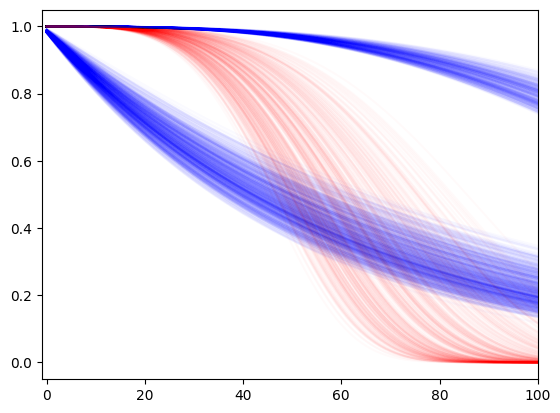

In [7]:
plt.xlim(-1,100)
for i in range(1,sv.shape[0]):
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    if (x_mat[i,0] == 1) & (x_mat[i,1] ==1):
    # if (x_mat[i,1] == 1):        
    # if ((x_mat[i,4]> .5) & (x_mat[i,3] > .5)):
        plt.plot(sv[i], color="red", alpha=.02)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(sv[i], color="blue", alpha=.02)
    # else:

In [8]:
x_mat.shape
out = pd.DataFrame(x_mat, columns = ["x_"+str(i) for i in range(10)])
out["time"] = event_dict["t_event"]
out["status"] = event_dict["status"]
out.to_csv("tmp_r.csv")

In [9]:
event_dict["t_event"]
pre = sb.get_surv_pre_train(y_time=event_dict["t_event"], y_status= event_dict["status"], x=x_mat, time_scale=10)
pos = sb.get_posterior_test(y_time=event_dict["t_event"], y_status=event_dict["status"], x= x_mat, time_scale=10)

In [70]:
I = 10
msk = pre["x"][:,0] <=I
pre["y"][msk].flatten().mean()

0.09606665849773312

In [71]:
trnr = pd.read_csv("trnr.csv").iloc[:,1:]
trnr = trnr.to_numpy()
trnry = trnr[:,0]
trnrx = trnr[:,1:]
tstr = pd.read_csv("tstr.csv").iloc[:,1:]
tstr = tstr.to_numpy()
# trnrx

In [60]:
# np.all(pre["x"][msk,:] == trnrx)
# tstr.shape
# pos["post_x"][msk2,:].shape
y2 = pre["y"][msk].flatten()
y2[y2==0] = -1
# y2[y2==0] = -np.abs(np.random.normal(0,1,y2[y2==0].shape[0]))
# y2[y2==1] = -np.abs(np.random.normal(0,1,y2[y2==1].shape[0]))
y2

array([-1., -1., -1., ..., -1., -1.,  1.])

In [797]:
# tstr.shape
# np.all(tstr == pos["post_x"][msk2,:])

True

In [225]:
event_dict

with pm.Model() as m1:
    x_data = pm.Data("x_data", pre["x"][msk,:])
    # x_data = pm.Data("x_data", trnrx)
    f = pb.BART(
        "f",
        X = x_data, 
        Y = pre["y"].flatten()[msk],
        # Y = y2,
        # Y = trnry.flatten(),
        m = 200,
        separate_trees=False,
        split_rules= [pb.ContinuousSplitRule] + [pb.OneHotSplitRule, pb.OneHotSplitRule] + [pb.ContinuousSplitRule]*8,
        # split_prior=[1,.2,.2,.5,.2,.5,.5,.5,.5,.5,.5],
        split_prior=[1,1,1,1,1,1,1,1,1,1,1],
        beta=.6
        # alpha=0.
    )
    
    # mu = pm.Deterministic("mu", pm.math.invlogit(f))
    mu = pm.Deterministic("mu", pm.math.invprobit(f))
    y_pred = pm.Bernoulli("y", p=mu, observed=pre["y"][msk].flatten(), shape=x_data.shape[0])
    # y_pred = pm.Bernoulli("y", p=mu, observed=trnry.flatten(), shape=x_data.shape[0])
    
    idata = pm.sample(chains=12, cores =12,tune=1000, draws=1000, 
                      compute_convergence_checks=False, random_seed=123,
                      pgbart={
                          "num_particles":10,
                          "batch":(.4,.8)
                          }
                      )

    # idata = pm.sample_posterior_predictive()

# I= 4
msk2 = pos["post_x"][:,0] <= I
pos["post_x"][msk2,:]
with m1:
    pm.set_data({"x_data":pos["post_x"][msk2,:]})
    # pm.set_data({"x_data":tstr})
    post = pm.sample_posterior_predictive(idata, var_names=["mu"], extend_inferencedata=False)

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 1_000 tune and 1_000 draw iterations (12_000 + 12_000 draws total) took 1597 seconds.
Sampling: [f]


Output()

In [ ]:
# trss = list(m1.basic_RVs[0].owner.op.all_trees)
# # for i in trss.
# # len(trss[0][0][3].tree_structure)
# ll = []
# for i in range(len(trss)):
#     # print(i)      
#     for j in range(trss[i][0].shape[0]):
#         ll.append(max(trss[i][0][j].tree_structure.keys()))
#     # print(len(trss[i][0][1].tree_structure))
#     # print(max(trss[i][0][1].tree_structure.keys()))
#         # print(j)
# # np.mean(ll)
# max(ll)

26

In [ ]:
# p1 = post.posterior_predictive["mu"].values.reshape(1200,-1).mean(0).reshape(5000,5)


In [ ]:
# msktmp = (x_mat[:,1] == 1) & (x_mat[:,0]==0)
# msktmp2 = (x_mat[:,1] == 1) & (x_mat[:,0]==1)
# tmp = x_mat[msktmp,:]
# tmp.shape
# event_dict["t_event"][msktmp].mean()
# event_dict["t_event"][msktmp2].mean()
# # event_dict["status"][msktmp].mean()
# tmpmsk =((pre["x"][:,1] == 1) & (pre["x"][:,2] == 1))
# pre["y"][tmpmsk].mean()


# event_dict["status"][msktmp2].mean()

0.12873796249366448

(-0.05, 1.0)

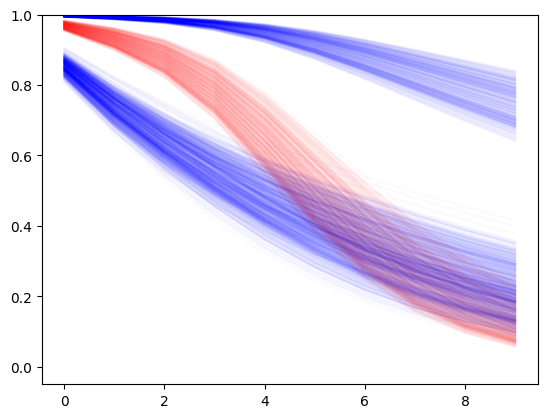

In [227]:
p1 = post.posterior_predictive["mu"].values.reshape(-1, 1400,10).mean(0)
# p1 = post.posterior_predictive["mu"].values.reshape(-1,I,1400).mean(0).T
# sb.get_sv_prob(post)
p2 = np.cumprod(1-p1,1)

for i in np.arange(1400):
# for i in np.arange(p2.shape[0]):
    # if ((x_mat[i,4]> .5) & (x_mat[i,3] > .5)):
    if (x_mat[i,0] == 1) & (x_mat[i,1] ==1):
    # if ((x_mat[i,1] == 1) & (x_mat[i,0]==0)):        
        plt.plot(p2[i,:], color="red", alpha=0.02)
        # plt.plot(sv[i], color="red", alpha=.02)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(p2[i,:], color="blue", alpha=0.02)
        # plt.plot(sv[i], color="blue", alpha=.02)
plt.ylim(-.05,1)    

# plt.xlim(0,11)

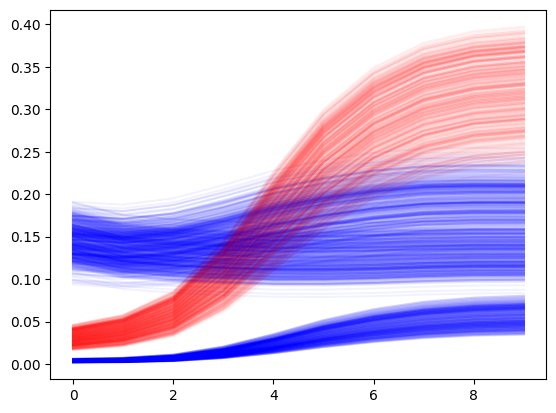

In [228]:
for i in np.arange(1400):
# for i in np.arange(p2.shape[0]):
    # if ((x_mat[i,4]> .5) & (x_mat[i,3] > .5)):
    if (x_mat[i,0] == 1) & (x_mat[i,1] ==1):
    # if (x_mat[i,1] == 1):        
        plt.plot(p1[i,:], color="red", alpha=0.05)
        # plt.plot(sv[i], color="red", alpha=.02)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(p1[i,:], color="blue", alpha=0.05)
        # plt.plot(sv[i], color="blue", alpha=.02)

In [290]:
p1[:,6].mean()

0.15523257406107727

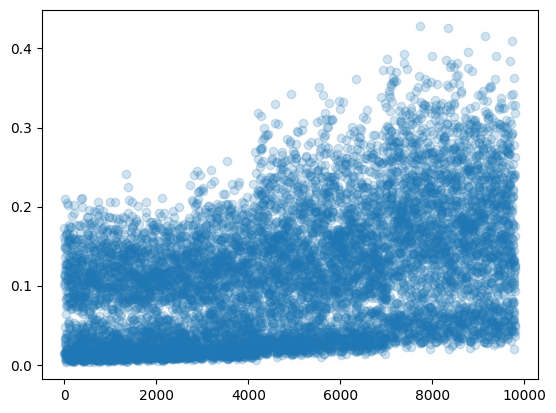

In [255]:
# plt.plot(p1.flatten(),"o",alpha=.2)
qq = post.posterior_predictive["mu"].values.mean(0).mean(0)

# plt.plot(range(qq.shape[0]), qq, "o", alpha=0.2)
qq2 = qq.reshape(1400,7).T.flatten()
plt.plot(range(qq.shape[0]), qq2, "o", alpha=0.2)
# qq

In [214]:
# del BSM
childs = mp.active_children()
for child in childs:
    print(child)
    # child.kill()

In [491]:
N_test = 1000

# shuffle to cut
# go = True
# # inflate = 100
# other_count = 0
# 
# tmp_seed = seed*inflate
tmp_seed = 11
rng = np.random.default_rng(tmp_seed)
scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)
# index =list(range(N + N_test))
# random.Random(tmp_seed).shuffle(index)

event_dict_upt = {
    "t_event":event_dict["t_event"][:N],
    "status": event_dict["status"][:N],
}
x_mat_t = x_mat[N:]
qnt_t = np.ceil(np.quantile(range(int(event_dict_upt["t_event"].max())), [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1])).astype("int")
# print(qnt_t)
print(qnt_t.shape)
print(qnt_t)

event_dict2 = get_quant_events(qnt_t=qnt_t, event=event_dict_upt)
event_dict2_upt = event_dict2

print(event_dict2["t_event"].shape)
print(np.unique(event_dict2["t_event"]).shape)
print(np.unique(event_dict["t_event"]).shape)
print(np.unique(event_dict2["t_event"]))
event_dict2_upt_tst = {
    "t_event": event_dict["t_event"][N:],
    "status": event_dict["status"][N:]
}


mean shape 2.2217174235000003
mean scale 91.19727379000001
503.0
mean time draws 84.81872310138517
cens mean 220.403
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
(1000, 1)
(11,)
(100,)
[ 5. 10. 20. 30. 40. 50. 60. 70. 80. 90. 99.]


In [495]:

if qnt_t.shape[0] == np.unique(event_dict2_upt["t_event"]).shape[0]:
    print("match size")
    go = False
    print(tmp_seed)
else:
    print("NO")
    go = True
cens_perc2 = event_dict2["status"][event_dict2["status"] == 0].shape[0]/event_dict2["status"].shape[0]        
uniq_t = np.unique(event_dict["t_event"])
true_t = sv_true["true_times"]

# cox model
cph_sv, cph_sv_test = cox_ph_3_2(x_mat[:N,:], event_dict_upt, times=qnt_t, test = x_mat_t)


match size
11


(-1.0, 100.0)

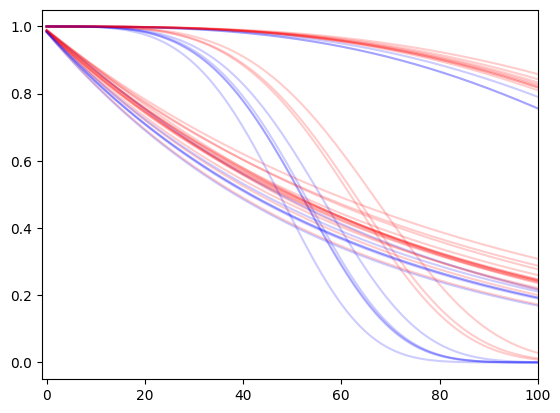

In [496]:
sv = sv_true["sv_true"]
# plt.plot(sv[1,:])
# plt.xlim(-1,200)
for i in range(40):
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    # if (x_mat[i,0] == 0) & (x_mat[i,1] ==1):
    # if (x_mat[i,0] == 1):
    if (x_mat[i,3] >.5):
        plt.plot(sv[i], color="red", alpha=.2)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(sv[i], color="blue", alpha=.2)
plt.xlim(-1,100)

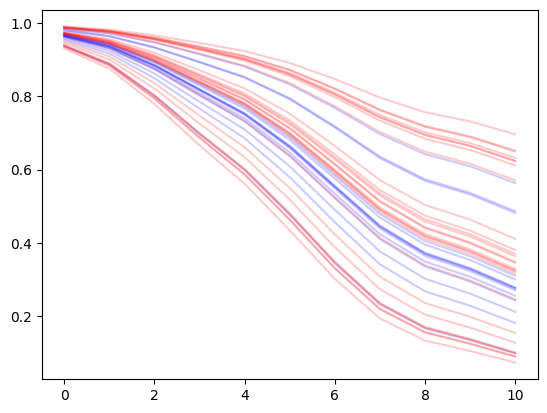

In [497]:
cph_sv
# plt.xlim(-1,200)
for i in range(40):
    # plt.plot(cph_sv[i], color="red", alpha=.2)
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    # if (x_mat[i,0] == 0) & (x_mat[i,1] ==1):
    if (x_mat[i,3] >.5):
    # if (x_mat[i,0] == 1):
        plt.plot(cph_sv[i], color="red", alpha=.2)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(cph_sv[i], color="blue", alpha=.2)

In [584]:
SPLIT_RULES3 = [
    # "pmb.OneHotSplitRule()",
    "pmb.ContinuousSplitRule()", # time
    # "pmb.ContinuousSplitRule()", 
    "pmb.OneHotSplitRule()", 
 	"pmb.ContinuousSplitRule()",
	# "pmb.OneHotSplitRule()", 
  	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()"
]
MODEL_DICT3 = {"trees": 20,
	"split_rules": SPLIT_RULES3,
	"beta":1
}

SAMPLER_DICT3 = { # new
	"draws": 100,
	"tune": 1000,
	"cores": 12,
	"chains": 12,
	"compute_convergence_checks": False,
	"pgbart":{
		"num_particles":10,
		"batch":(.5,.1)
		}
}

model_dict = MODEL_DICT3
sampler_dict = SAMPLER_DICT3
# pb_sv, pb_sv_test = get_py_bart_surv3_2(x_mat=x_mat[index[:N],:], event_dict=event_dict2_upt, model_dict=model_dict, sampler_dict=sampler_dict, test = x_mat_t)
pb_sv, pb_sv_test = get_py_bart_surv3_2(x_mat=x_mat[:N,:], event_dict=event_dict2_upt, model_dict=model_dict, sampler_dict=sampler_dict, test = x_mat_t)
# p_sv = pb_sv["sv"].mean(0)
pb_svm = pb_sv["sv"].mean(0)
p_sv_testm = pb_sv_test["sv"].mean(0)

/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 1_000 tune and 100 draw iterations (12_000 + 1_200 draws total) took 81 seconds.


In [502]:
pb_svm.shape

(1000, 11)

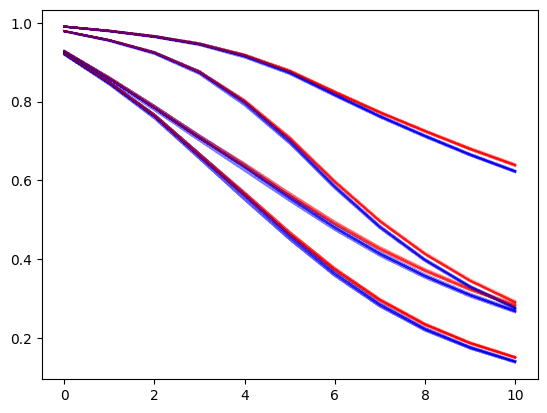

In [585]:
pb_svm
for i in range(pb_svm.shape[0]):
    if (x_mat[i,3] >.5):
        plt.plot(pb_svm[i], color="red", alpha=.02)
    else:
        plt.plot(pb_svm[i], color="blue", alpha=.02)

In [569]:
r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t = get_r_bart3_2(
    event_dict2_upt, 
    x_mat=x_mat[:N,:], 
    x_mat_tst = x_mat[N:,:],
    event_dict_tst = event_dict2_upt_tst
)

Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 0 0 1 0 0 1 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:1000, 1:10] 1 0 0 1 1 1 0 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6752, 11, 11000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.462000
xp1,xp[np*p]: 5.000000, 0.462000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.39142
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

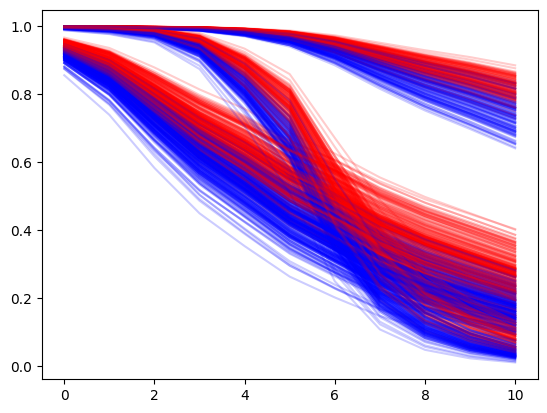

In [507]:
# r_sv.shape
# pb_svm
for i in range(r_sv.shape[0]):
    # plt.plot(pb_svm[i], color="red", alpha=.2)
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    # if (x_mat[i,0] == 0) & (x_mat[i,1] ==1):
    # if (x_mat[i,0] == 1):
    if (x_mat[i,3] >.5):
        plt.plot(r_sv[i], color="red", alpha=.2)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(r_sv[i], color="blue", alpha=.2)

In [232]:

# test plot

pb_svm.shape
# true_trn[:,1].shape
sv_true["sv_true"].shape

(5000, 517)

In [572]:
time_indx = [np.where(true_t == i)[0][0] for i in qnt_t]
true_trn = sv_true["sv_true"][:, time_indx][:N,:]
true_test = sv_true["sv_true"][:, time_indx][N:,:]

p_rmse = []
r_rmse = []
c_rmse = []
p_bias = []
r_bias = []
c_bias = []

p_mabs = []
r_mabs = []
c_mabs = []

for i in range(true_trn.shape[1]):
    p_rmse.append(rmse(true_trn[:,i], pb_svm[:,i]))
    r_rmse.append(rmse(true_trn[:,i], r_sv[:,i]))
    c_rmse.append( rmse(true_trn[:,i], cph_sv[:,i]))
    p_bias.append(bias(true_trn[:,i], pb_svm[:,i]))
    r_bias.append(bias(true_trn[:,i], r_sv[:,i]))
    c_bias.append(bias(true_trn[:,i], cph_sv[:,i]))

    p_mabs.append(medabs(true_trn[:,i], pb_svm[:,i]))
    r_mabs.append(medabs(true_trn[:,i], r_sv[:,i]))
    c_mabs.append(medabs(true_trn[:,i], cph_sv[:,i]))


df_tst2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                            r_mabs, c_mabs]).T
df_tst2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs".split(",")


df_tst2

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs
0,0.012041,0.009710,0.027472,0.001434,0.000371,0.001480,0.008476,0.003793,0.019363
1,0.023920,0.017821,0.052992,0.004239,-0.001355,-0.002693,0.015305,0.007261,0.035736
2,0.050784,0.031597,0.097188,-0.008606,-0.011305,-0.012949,0.046206,0.010203,0.067264
3,0.065454,0.038602,0.123226,-0.009255,-0.014036,-0.009675,0.060090,0.014763,0.096969
4,0.067844,0.048444,0.132907,-0.012241,-0.017698,-0.014521,0.054081,0.024494,0.097412
5,0.064882,0.058747,0.136048,-0.010679,-0.017886,-0.009981,0.041421,0.027079,0.114097
6,0.074502,0.071017,0.155511,-0.005339,-0.005179,0.003633,0.043127,0.033215,0.152448
7,0.087196,0.073616,0.183788,-0.001161,0.005128,0.019158,0.054506,0.036517,0.154400
8,0.091102,0.065889,0.201341,0.000426,0.003454,0.017807,0.063660,0.039930,0.163259
9,0.086983,0.056237,0.205359,0.000082,-0.001134,0.003070,0.064478,0.038077,0.162606


In [573]:
p_rmse = []
r_rmse = []
c_rmse = []


p_bias = []
r_bias = []
c_bias = []

p_mabs = []
r_mabs = []
c_mabs = []

p_rsq = []
r_rsq = []
c_rsq = []



# res
for i in range(true_trn.shape[1]):
    p_rmse.append(rmse(true_test[:,i], p_sv_testm[:,i]))
    r_rmse.append(rmse(true_test[:,i], r_sv_t[:,i]))
    c_rmse.append( rmse(true_test[:,i], cph_sv_test[:,i]))

    p_bias.append(bias(true_test[:,i], p_sv_testm[:,i]))
    r_bias.append(bias(true_test[:,i], r_sv_t[:,i]))
    c_bias.append(bias(true_test[:,i], cph_sv_test[:,i]))

    p_mabs.append(medabs(true_test[:,i], p_sv_testm[:,i]))
    r_mabs.append(medabs(true_test[:,i], r_sv_t[:,i]))
    c_mabs.append(medabs(true_test[:,i], cph_sv_test[:,i]))

    p_rsq.append(rsqr(true_test[:,i], p_sv_testm[:,i]))
    r_rsq.append(rsqr(true_test[:,i], r_sv_t[:,i]))
    c_rsq.append(rsqr(true_test[:,i], cph_sv_test[:,i]))

deciles= [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1][::-1]
itersss = np.repeat(tmp_seed, 11)
nnn = np.repeat(N, 11)
df_tst2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                r_mabs, c_mabs, p_rsq, r_rsq, c_rsq, deciles, itersss, nnn]).T

df_tst2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n".split(",")
df_tst2


,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n
0,0.012094,0.010007,0.028601,0.001737,0.000608,0.001012,0.009090,0.003918,0.023417,0.891605,0.925782,0.393785,1.00,11.0,1000.0
1,0.024083,0.018215,0.055155,0.004947,-0.000830,-0.003334,0.016376,0.007377,0.042589,0.884678,0.934031,0.395131,0.90,11.0,1000.0
2,0.051221,0.031670,0.100787,-0.007291,-0.010551,-0.013779,0.047106,0.009583,0.076588,0.844273,0.940465,0.397056,0.80,11.0,1000.0
3,0.066163,0.038550,0.127471,-0.007753,-0.013171,-0.011238,0.063105,0.015344,0.106535,0.853490,0.950261,0.456170,0.70,11.0,1000.0
4,0.068915,0.048793,0.137227,-0.011524,-0.016794,-0.017764,0.054554,0.027220,0.102227,0.880879,0.940286,0.527676,0.60,11.0,1000.0
5,0.068235,0.061483,0.140776,-0.011505,-0.017576,-0.015891,0.044198,0.029614,0.119211,0.904992,0.922866,0.595614,0.50,11.0,1000.0
6,0.079670,0.075071,0.159920,-0.007500,-0.003808,-0.004758,0.046145,0.035826,0.157675,0.898769,0.910119,0.592127,0.40,11.0,1000.0
7,0.090633,0.077773,0.186235,-0.004145,0.006918,0.009521,0.057121,0.039742,0.154042,0.894410,0.922249,0.554170,0.30,11.0,1000.0
8,0.092009,0.068190,0.202911,-0.003041,0.005149,0.007698,0.065665,0.043433,0.166563,0.902743,0.946580,0.526982,0.20,11.0,1000.0
9,0.086837,0.056780,0.207803,-0.003923,0.000037,-0.007443,0.065921,0.040885,0.164087,0.915056,0.963683,0.513561,0.10,11.0,1000.0


In [166]:


def big_loop(seed, N):
    N_test = 400
    # shuffle to cut
    go = True
    inflate = 100
    other_count = 0
    while go:
        tmp_seed = seed*inflate
        rng = np.random.default_rng(tmp_seed)
        scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)
        # index =list(range(N + N_test))
        # random.Random(tmp_seed).shuffle(index)

        event_dict_upt = {
            "t_event":event_dict["t_event"][:N],
            "status": event_dict["status"][:N],
        }
        x_mat_t = x_mat[N:,:]
        qnt_t = np.ceil(np.quantile(range(int(event_dict_upt["t_event"].max())), [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1])).astype("int")
        print(qnt_t.shape)
        print(qnt_t)

        event_dict2 = get_quant_events(qnt_t=qnt_t, event=event_dict_upt)
        event_dict2_upt = event_dict2
        # print(event_dict2["t_event"].shape)
        # print(np.unique(event_dict2["t_event"]).shape)
        # print(np.unique(event_dict["t_event"]).shape)
        # print(np.unique(event_dict2["t_event"]))
        event_dict2_upt_tst = {
            "t_event": event_dict["t_event"][N:],
            "status": event_dict["status"][N:]
        }
        if qnt_t.shape[0] == np.unique(event_dict2_upt["t_event"]).shape[0]:
            print("match size")
            go = False
            print(tmp_seed)
        else:
            print("NO")
            go = True
        if other_count > 10:
            assert(False)
        inflate += 100
        other_count += 1


    cens_perc2 = event_dict2["status"][event_dict2["status"] == 0].shape[0]/event_dict2["status"].shape[0]        
    print(cens_perc2)
    # uniq_t = np.unique(event_dict["t_event"])
    true_t = sv_true["true_times"]
    # cox model
    cph_sv, cph_sv_test = cox_ph_3_2(x_mat[:N,:], event_dict_upt, times=qnt_t, test = x_mat_t)
    
    # P-bart
    model_dict = MODEL_DICT3
    sampler_dict = SAMPLER_DICT3
    pb_sv_trn, pb_sv_test = get_py_bart_surv3_2(
        x_mat=x_mat[:N,:], 
        event_dict=event_dict2_upt, 
        model_dict=model_dict, 
        sampler_dict=sampler_dict, 
        test = x_mat_t)
    p_sv = pb_sv_trn["sv"].mean(0)
    p_sv_test = pb_sv_test["sv"].mean(0)

    # r-BART
    r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t = get_r_bart3_2(
        event_dict2_upt, 
        x_mat=x_mat[:N,:], 
        x_mat_tst = x_mat[N:,:],
        event_dict_tst = event_dict2_upt_tst
    )
    # print(r_sv.shape)
    # print(r_sv)
        
    # plt
    plt.figure()
    sv = sv_true["sv_true"]
    for i in range(20):
        plt.plot(p_sv[i], color="green", alpha=.4, label="p")
        plt.plot(r_sv[i], color="blue", alpha=.4,label= 'r')
        plt.plot(cph_sv[i], color="red", alpha=.1, label="c")
    plt.show()

    # set up the times
    time_indx = [np.where(true_t == i)[0][0] for i in qnt_t]
    true_trn = sv_true["sv_true"][:, time_indx][:N,:]
    true_test = sv_true["sv_true"][:, time_indx][N:,:]

    # trn
    p_rmse = []
    r_rmse = []
    c_rmse = []
    p_bias = []
    r_bias = []
    c_bias = []
    p_mabs = []
    r_mabs = []
    c_mabs = []
    p_rsq = []
    r_rsq = []
    c_rsq = []
    # res
    for i in range(true_trn.shape[1]):
        p_rmse.append(rmse(true_trn[:,i], p_sv[:,i]))
        r_rmse.append(rmse(true_trn[:,i], r_sv[:,i]))
        c_rmse.append( rmse(true_trn[:,i], cph_sv[:,i]))

        p_bias.append(bias(true_trn[:,i], p_sv[:,i]))
        r_bias.append(bias(true_trn[:,i], r_sv[:,i]))
        c_bias.append(bias(true_trn[:,i], cph_sv[:,i]))

        p_mabs.append(medabs(true_trn[:,i], p_sv[:,i]))
        r_mabs.append(medabs(true_trn[:,i], r_sv[:,i]))
        c_mabs.append(medabs(true_trn[:,i], cph_sv[:,i]))

        p_rsq.append(rsqr(true_trn[:,i], p_sv[:,i]))
        r_rsq.append(rsqr(true_trn[:,i], r_sv[:,i]))
        c_rsq.append(rsqr(true_trn[:,i], cph_sv[:,i]))

    deciles= [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1][::-1]
    itersss = np.repeat(tmp_seed, 11)
    nnn = np.repeat(N, 11)
    df_trn2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                            r_mabs, c_mabs, p_rsq, r_rsq, c_rsq, deciles, itersss, nnn]).T

    df_trn2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n".split(",")


    # tst
    p_rmse = []
    r_rmse = []
    c_rmse = []
    p_bias = []
    r_bias = []
    c_bias = []
    p_mabs = []
    r_mabs = []
    c_mabs = []
    p_rsq = []
    r_rsq = []
    c_rsq = []
    # res
    for i in range(true_test.shape[1]):
        p_rmse.append(rmse(true_test[:,i], p_sv_test[:,i]))
        r_rmse.append(rmse(true_test[:,i], r_sv_t[:,i]))
        c_rmse.append( rmse(true_test[:,i], cph_sv_test[:,i]))

        p_bias.append(bias(true_test[:,i], p_sv_test[:,i]))
        r_bias.append(bias(true_test[:,i], r_sv_t[:,i]))
        c_bias.append(bias(true_test[:,i], cph_sv_test[:,i]))

        p_mabs.append(medabs(true_test[:,i], p_sv_test[:,i]))
        r_mabs.append(medabs(true_test[:,i], r_sv_t[:,i]))
        c_mabs.append(medabs(true_test[:,i], cph_sv_test[:,i]))

        p_rsq.append(rsqr(true_test[:,i], p_sv_test[:,i]))
        r_rsq.append(rsqr(true_test[:,i], r_sv_t[:,i]))
        c_rsq.append(rsqr(true_test[:,i], cph_sv_test[:,i]))

    deciles= [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1][::-1]
    itersss = np.repeat(tmp_seed, 11)
    nnn = np.repeat(N, 11)
    df_tst2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                            r_mabs, c_mabs, p_rsq, r_rsq, c_rsq, deciles, itersss, nnn]).T

    df_tst2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n".split(",")


    return(df_trn2, df_tst2)

mean shape 2.37043017825
mean scale 92.9066897
472.0
mean time draws 87.22964037977032
cens mean 240.21625
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
100
0.47


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 27 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 1 1 0 0 1 1 1 1 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 0 0 1 1 0 0 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2740, 11, 4400
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.342000
xp1,xp[np*p]: 5.000000, 0.342000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.42297
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 100

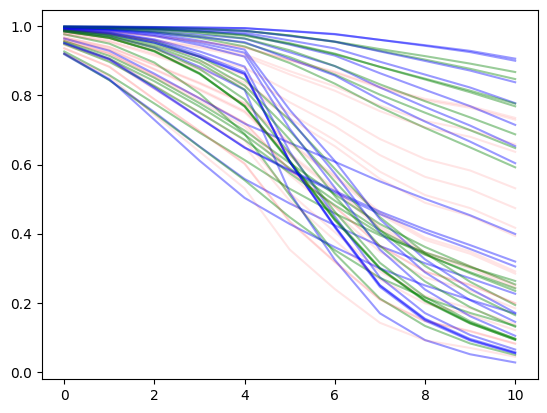

mean shape 2.278958205125
mean scale 93.302911175
500.0
mean time draws 85.92113250041791
cens mean 249.91375
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
200
0.415


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 26 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 1 1 0 0 1 1 1 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 1 1 1 1 1 1 0 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2782, 11, 4400
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.389000
xp1,xp[np*p]: 5.000000, 0.389000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.37793
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 100

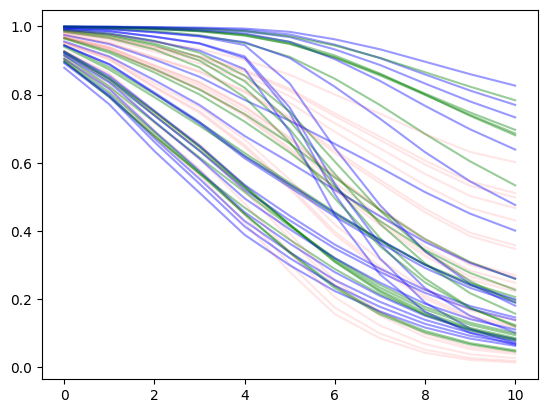

mean shape 2.197371486875
mean scale 91.129980925
497.0
mean time draws 83.14689500115637
cens mean 245.71
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
300
0.4225


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 25 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 1 1 0 0 1 1 0 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 1 0 1 0 0 0 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2683, 11, 4400
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.500000
xp1,xp[np*p]: 5.000000, 0.500000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.36518
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 100

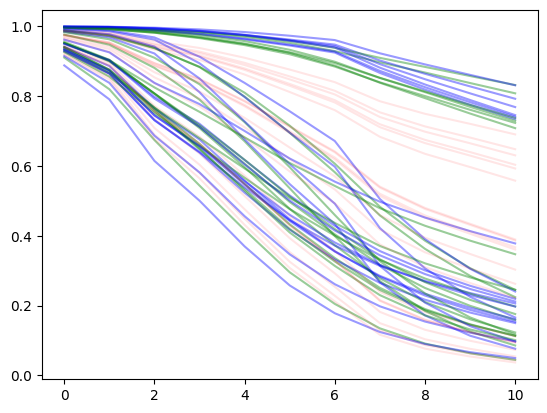

mean shape 2.22011094825
mean scale 87.522900075
503.0
mean time draws 85.16492193739154
cens mean 214.68375
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
400
0.415


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 25 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 0 1 1 0 0 0 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 1 1 1 0 1 1 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2666, 11, 4400
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.131000
xp1,xp[np*p]: 5.000000, 0.131000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.3546
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1000

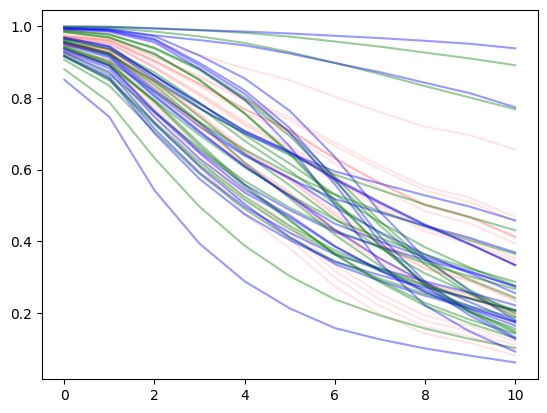

mean shape 2.265962263125
mean scale 92.12451929999999
516.0
mean time draws 86.5711696823722
cens mean 226.19375
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
500
0.475


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 25 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 1 1 1 0 0 1 0 1 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 0 1 1 0 0 1 1 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2745, 11, 4400
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.846000
xp1,xp[np*p]: 5.000000, 0.846000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.429
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1000 

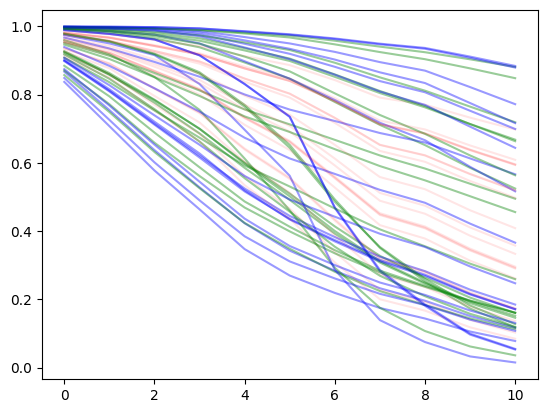

mean shape 2.24140297925
mean scale 92.12939377499998
494.0
mean time draws 87.40168619106797
cens mean 217.02875
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
600
0.4525


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 24 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 0 0 1 1 1 1 0 0 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 0 0 0 0 1 1 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2690, 11, 4400
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.956000
xp1,xp[np*p]: 5.000000, 0.956000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.39563
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 100

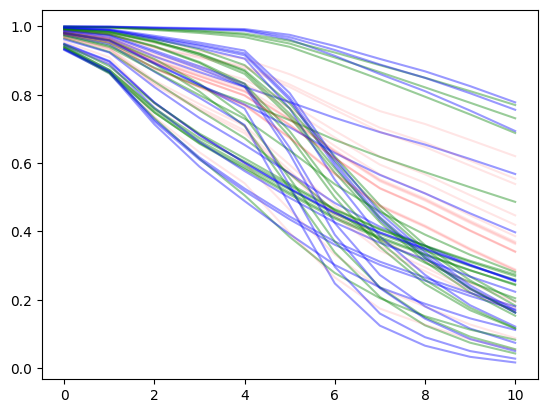

mean shape 2.24737979075
mean scale 92.691345625
517.0
mean time draws 85.73719319653311
cens mean 228.18875
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
700
0.4525


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 24 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 0 0 1 0 1 0 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 1 0 0 0 0 1 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2715, 11, 4400
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.065000
xp1,xp[np*p]: 5.000000, 0.065000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.40063
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 100

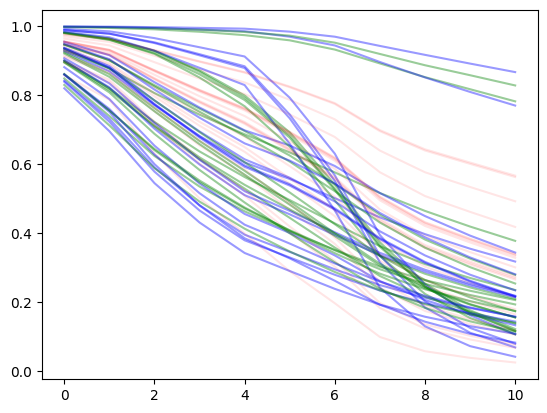

mean shape 2.2200148028749997
mean scale 89.87031465
481.0
mean time draws 84.8121966366794
cens mean 222.18875
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
800
0.4675


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 24 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 0 0 0 1 0 1 1 1 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 0 1 1 0 0 0 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2685, 11, 4400
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.440000
xp1,xp[np*p]: 5.000000, 0.440000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.4096
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1000

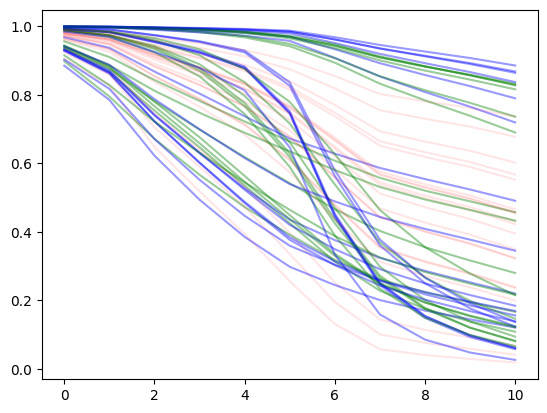

mean shape 2.2253467540000003
mean scale 93.711045925
495.0
mean time draws 86.74674090333338
cens mean 243.78625
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
900
0.4475


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 25 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 0 0 1 0 1 0 1 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 0 1 1 0 0 1 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2722, 11, 4400
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.473000
xp1,xp[np*p]: 5.000000, 0.473000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.39711
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 100

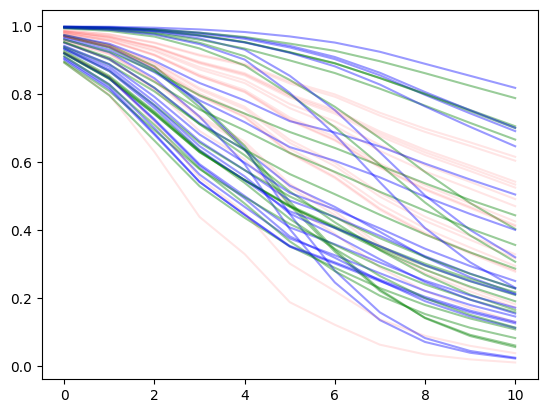

mean shape 2.25479382625
mean scale 91.031921275
478.0
mean time draws 81.32001517200891
cens mean 237.69625
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
1000
0.43


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 24 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:400, 1:10] 1 1 0 0 1 0 0 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 0 1 1 0 1 0 1 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 2730, 11, 4400
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.487000
xp1,xp[np*p]: 5.000000, 0.487000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.3818
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1000

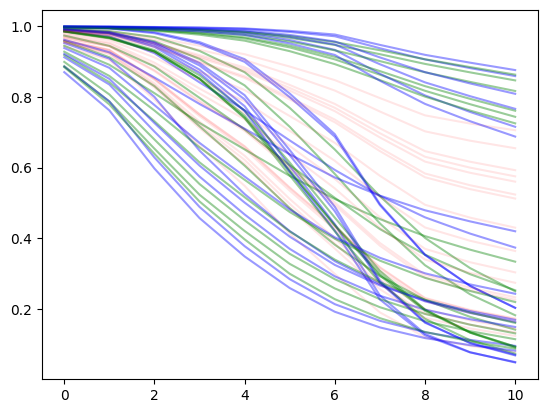

In [ ]:
df_trn = pd.DataFrame()
df_tst = pd.DataFrame()
for i in [1,2,3,4,5,6,7,8,9,10]:
# for i in [1]:
    trn_df, tst_df = big_loop(seed = i, N=400)
    df_trn = pd.concat([trn_df, df_trn])
    df_tst = pd.concat([tst_df, df_tst])

df_trn.to_csv("complex1_N_400_trn.csv")
df_tst.to_csv("complex1_N_400_tst.csv")

In [169]:
df_trn

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n
0,0.017103,0.018584,0.032719,0.002834,0.003977,0.001851,0.010768,0.008171,0.024944,0.772440,0.731322,0.167190,1.00,100.0,400.0
1,0.032355,0.033897,0.062798,0.007782,0.006873,0.000437,0.022580,0.015851,0.048923,0.782795,0.761607,0.181767,0.90,100.0,400.0
2,0.058263,0.051488,0.113939,-0.002531,-0.001191,-0.004589,0.044810,0.026747,0.092293,0.790805,0.836628,0.199959,0.80,100.0,400.0
3,0.078736,0.064470,0.147759,-0.008193,-0.005879,-0.011635,0.054972,0.027445,0.119405,0.784374,0.855434,0.240617,0.70,100.0,400.0
4,0.086987,0.076668,0.161427,-0.014040,-0.022757,-0.026732,0.054728,0.030553,0.114354,0.802159,0.846314,0.318658,0.60,100.0,400.0
5,0.092880,0.098310,0.159087,-0.009934,-0.004516,-0.007511,0.063193,0.055829,0.118497,0.818566,0.796731,0.467712,0.50,100.0,400.0
6,0.102699,0.110839,0.172784,-0.021269,-0.017656,-0.021025,0.063742,0.060868,0.134929,0.833115,0.805610,0.527620,0.40,100.0,400.0
7,0.111662,0.113357,0.195467,-0.031058,-0.023598,-0.020116,0.077604,0.069237,0.169392,0.847627,0.842965,0.533074,0.30,100.0,400.0
8,0.115342,0.110740,0.214388,-0.038935,-0.035542,-0.029253,0.085369,0.068683,0.185762,0.858477,0.869546,0.511066,0.20,100.0,400.0
9,0.113135,0.108295,0.224591,-0.040073,-0.041551,-0.048817,0.089205,0.066061,0.196242,0.867792,0.878862,0.478988,0.10,100.0,400.0


mean shape 2.3106464595
mean scale 92.93198992857143
502.0
mean time draws 86.2749032151697
cens mean 223.28
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
100
0.456


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 46 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 1 1 0 0 1 1 1 1 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 0 0 1 1 1 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6781, 11, 11000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.476000
xp1,xp[np*p]: 5.000000, 0.476000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.40357
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

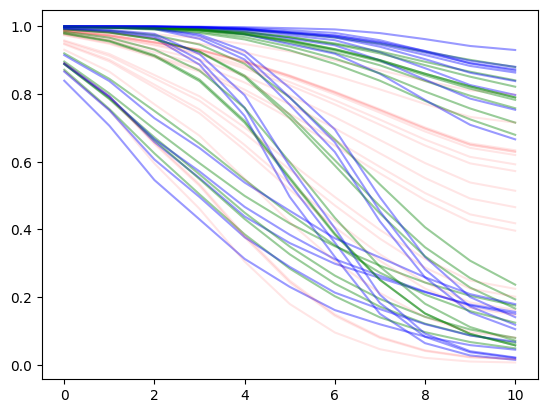

mean shape 2.2431281760714286
mean scale 91.95479307142858
513.0
mean time draws 84.59511170017461
cens mean 239.605
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
200
0.458


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 48 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 1 1 0 0 1 1 1 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 0 0 0 0 0 0 1 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6837, 11, 11000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.941000
xp1,xp[np*p]: 5.000000, 0.941000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.40997
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

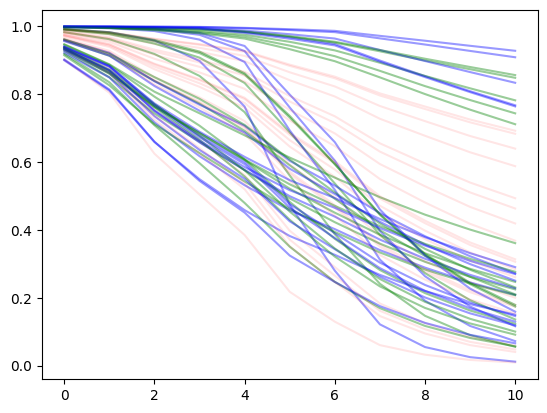

mean shape 2.264615216857143
mean scale 90.70964512857142
513.0
mean time draws 85.34565075098062
cens mean 224.18357142857144
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
300
0.412


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 47 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 1 1 0 0 1 1 0 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 1 1 1 0 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6774, 11, 11000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.357000
xp1,xp[np*p]: 5.000000, 0.357000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.36071
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

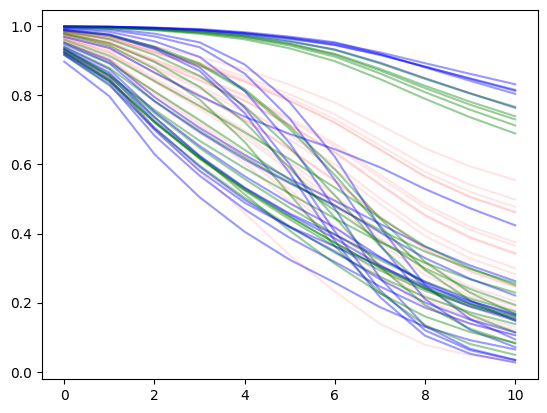

mean shape 2.258054816357143
mean scale 92.37499647142857
510.0
mean time draws 86.05743465157396
cens mean 227.84428571428572
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
400
0.449


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 47 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 0 1 1 0 0 0 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 0 1 1 1 0 1 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6694, 11, 11000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.279000
xp1,xp[np*p]: 5.000000, 0.279000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.38968
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

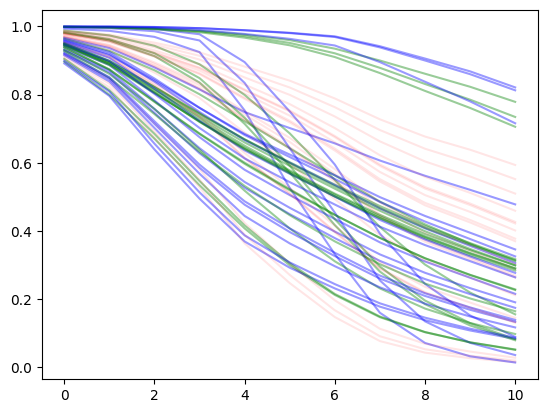

mean shape 2.2618579332857145
mean scale 92.14660865714286
502.0
mean time draws 83.39345381478653
cens mean 227.49857142857144
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
500
0.445


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 46 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 1 1 1 0 0 1 0 1 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 1 0 1 1 1 1 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6710, 11, 11000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.949000
xp1,xp[np*p]: 5.000000, 0.949000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.38706
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

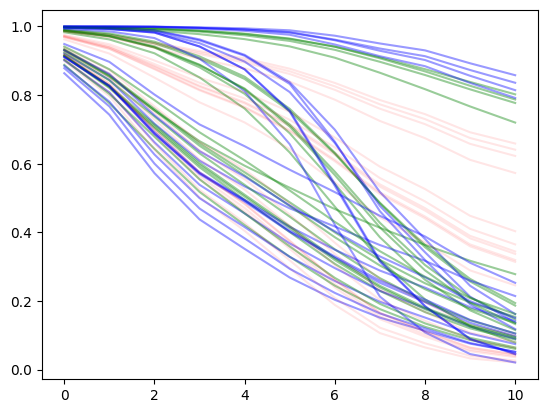

mean shape 2.229954266285714
mean scale 89.59269432857143
502.0
mean time draws 84.18991563144758
cens mean 223.50214285714284
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
600
0.455


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 48 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 0 0 1 1 1 1 0 0 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 0 0 1 1 0 1 1 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6815, 11, 11000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.712000
xp1,xp[np*p]: 5.000000, 0.712000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.40527
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

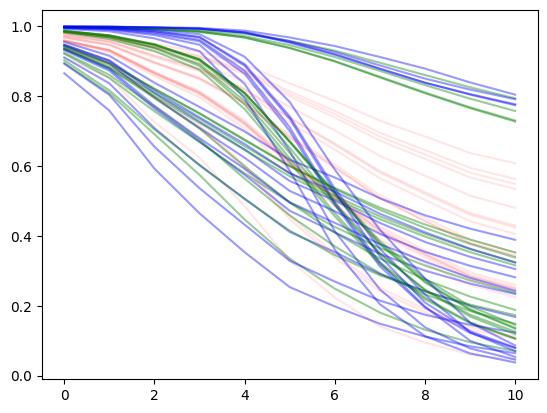

mean shape 2.2647772951428573
mean scale 91.43773765714286
497.0
mean time draws 85.77403908820271
cens mean 243.7692857142857
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
700
0.422


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 45 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 0 0 1 0 1 0 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 1 1 0 1 1 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6747, 11, 11000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.661000
xp1,xp[np*p]: 5.000000, 0.661000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.36793
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

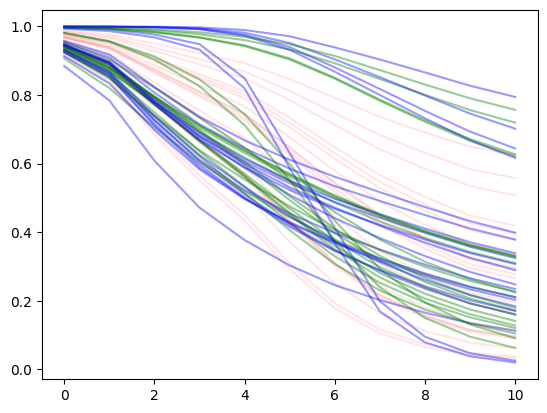

mean shape 2.2278972150714287
mean scale 90.86045654285714
516.0
mean time draws 84.40116591379471
cens mean 239.20142857142858
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
800
0.428


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 44 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 0 0 0 1 0 1 1 1 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 0 0 1 1 1 1 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6749, 11, 11000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.513000
xp1,xp[np*p]: 5.000000, 0.513000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.37379
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

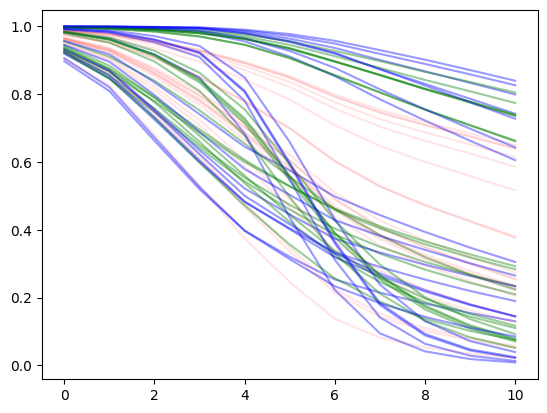

mean shape 2.238811271214286
mean scale 90.37678098571429
506.0
mean time draws 85.0518365806072
cens mean 224.02928571428572
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
900
0.44


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 45 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 0 0 1 0 1 0 1 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 0 0 1 1 0 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6629, 11, 11000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.586000
xp1,xp[np*p]: 5.000000, 0.586000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.37557
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

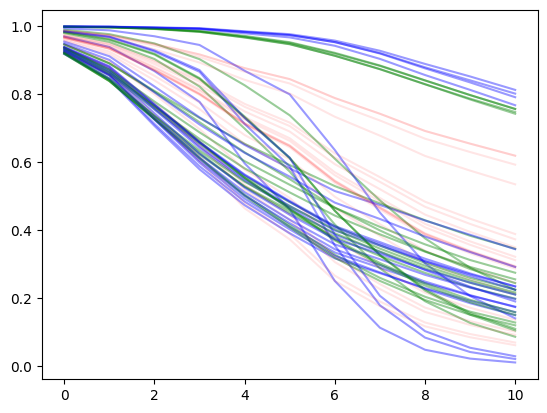

mean shape 2.2391006306428567
mean scale 90.97680705714286
498.0
mean time draws 82.65830572117505
cens mean 218.575
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
1000
0.439


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 44 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 1 1 0 0 1 0 0 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 1 1 1 1 1 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6666, 11, 11000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.593000
xp1,xp[np*p]: 5.000000, 0.593000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.37763
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

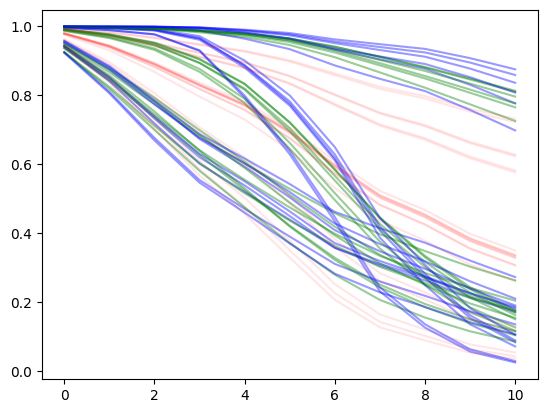

In [174]:
df_trn = pd.DataFrame()
df_tst = pd.DataFrame()
for i in [1,2,3,4,5,6,7,8,9,10]:
# for i in [1]:
    trn_df, tst_df = big_loop(seed = i, N=1000)
    df_trn = pd.concat([trn_df, df_trn])
    df_tst = pd.concat([tst_df, df_tst])

df_trn.to_csv("complex1_N_1000_trn.csv")
df_tst.to_csv("complex1_N_1000_tst.csv")

In [176]:
df_trn.groupby("deciles").mean()
# df_tst.groupby("deciles").mean()

# for i in []

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,seed,n
deciles,,,,,,,,,,,,,,
0.05,0.084795,0.069366,0.200382,-0.001938,-0.002912,-0.001667,0.069916,0.043169,0.171000,0.917218,0.944017,0.538977,550.0,1000.0
0.10,0.092045,0.072101,0.206853,-0.006029,-0.004277,0.000029,0.071831,0.046468,0.179534,0.906018,0.941877,0.526890,550.0,1000.0
0.20,0.096389,0.077138,0.204279,-0.006367,-0.003981,0.000416,0.067924,0.048086,0.177381,0.893892,0.931703,0.525718,550.0,1000.0
0.30,0.093760,0.081652,0.187396,-0.004092,-0.000003,0.006619,0.059060,0.046104,0.165312,0.886006,0.913276,0.547655,550.0,1000.0
0.40,0.081191,0.080425,0.161477,0.001047,-0.000577,0.008289,0.047732,0.041937,0.146818,0.892570,0.894583,0.579070,550.0,1000.0
0.50,0.066255,0.070923,0.142076,0.006216,0.003043,0.009423,0.039691,0.037349,0.122101,0.907814,0.894674,0.583080,550.0,1000.0
0.60,0.060805,0.061902,0.138287,0.007181,0.002292,0.007307,0.038701,0.028394,0.111951,0.904266,0.901637,0.515176,550.0,1000.0
0.70,0.056149,0.052279,0.127901,0.005350,0.001541,0.004514,0.039151,0.018908,0.106070,0.891557,0.905837,0.445052,550.0,1000.0
0.80,0.042606,0.041983,0.099345,0.003956,0.002184,0.002849,0.030141,0.014894,0.079693,0.888772,0.891523,0.403635,550.0,1000.0


mean shape 2.280541130636364
mean scale 92.45487049545456
513.0
mean time draws 85.1980105816447
cens mean 227.01022727272726
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
100
0.442


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 163 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 1 1 0 0 1 1 1 1 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 1 1 1 0 0 1 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 26924, 11, 44000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.894000
xp1,xp[np*p]: 5.000000, 0.894000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.38583
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

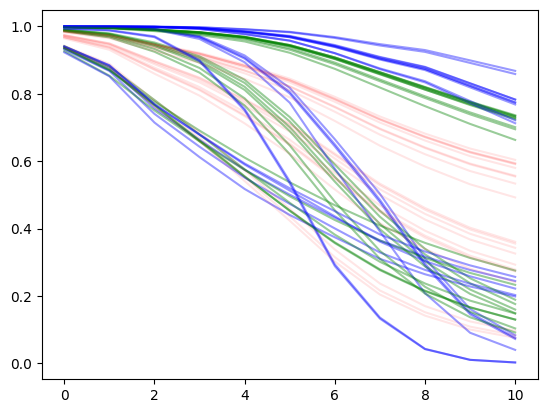

mean shape 2.2506378619772724
mean scale 91.34205107727271
513.0
mean time draws 84.76648634734781
cens mean 227.22227272727272
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
200
0.43975


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 171 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 1 1 0 0 1 1 1 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 1 1 1 1 0 1 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 26996, 11, 44000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.425000
xp1,xp[np*p]: 5.000000, 0.425000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.38509
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

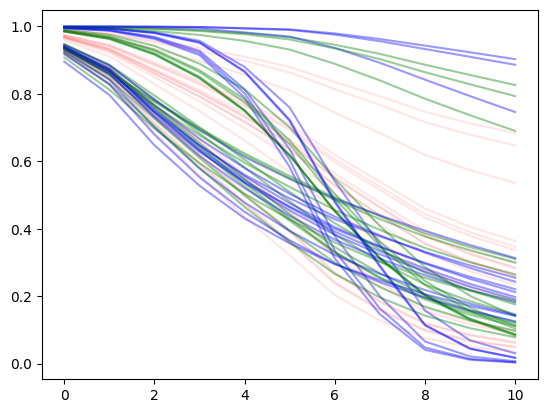

mean shape 2.2662425401363633
mean scale 92.35008087727273
517.0
mean time draws 87.23600284570328
cens mean 230.83954545454546
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
300
0.45275


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 165 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 1 1 0 0 1 1 0 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 0 0 0 1 1 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 27648, 11, 44000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.755000
xp1,xp[np*p]: 5.000000, 0.755000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.41065
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

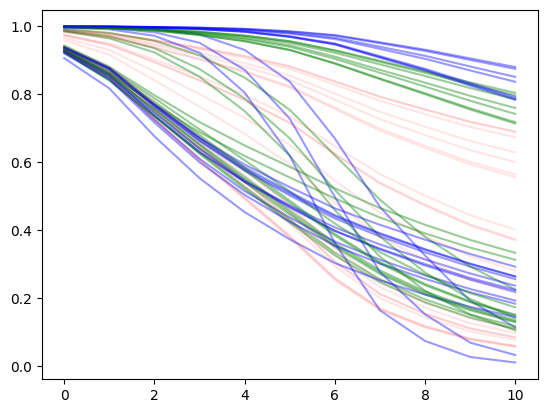

mean shape 2.2284433602045453
mean scale 91.77253787727273
504.0
mean time draws 84.9042133513609
cens mean 233.15431818181818
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
400
0.43675


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 172 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 0 1 1 0 0 0 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 1 0 1 1 0 0 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 27350, 11, 44000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.436000
xp1,xp[np*p]: 5.000000, 0.436000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.38926
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

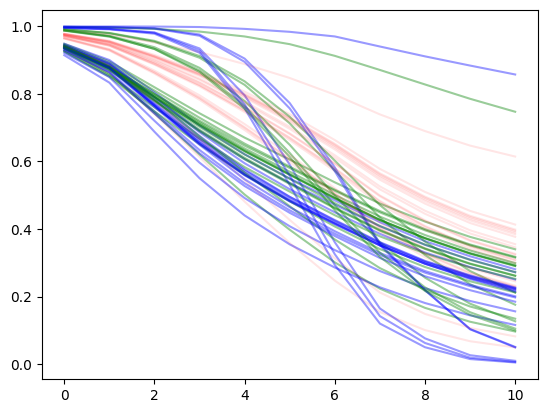

mean shape 2.2647627462954545
mean scale 91.63041469545456
496.0
mean time draws 85.12641655937573
cens mean 233.84318181818182
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
500
0.43975


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 168 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 1 1 1 0 0 1 0 1 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 0 1 0 1 0 0 1 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 26997, 11, 44000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.100000
xp1,xp[np*p]: 5.000000, 0.100000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.38511
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

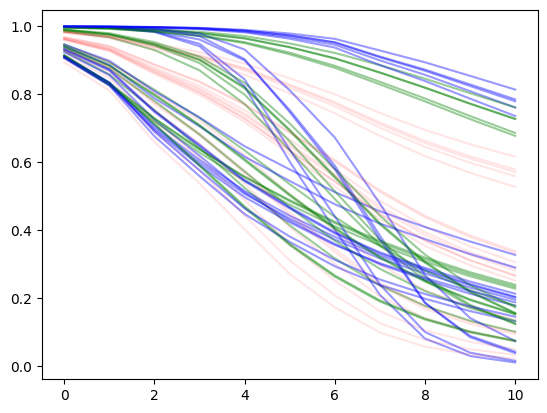

mean shape 2.25795580325
mean scale 91.21519578636365
513.0
mean time draws 85.08756295637134
cens mean 225.89
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
600
0.43825


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 160 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 0 0 1 1 1 1 0 0 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 1 0 0 1 1 0 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 27351, 11, 44000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.191000
xp1,xp[np*p]: 5.000000, 0.191000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.39073
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

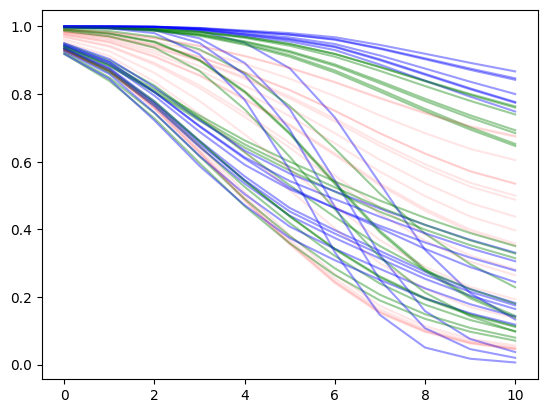

mean shape 2.263172215977273
mean scale 92.16914895909089
500.0
mean time draws 85.06781657142484
cens mean 229.48818181818183
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
700
0.43175


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 160 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 0 0 1 0 1 0 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 1 0 1 1 0 0 0 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 26893, 11, 44000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.722000
xp1,xp[np*p]: 5.000000, 0.722000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.37529
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

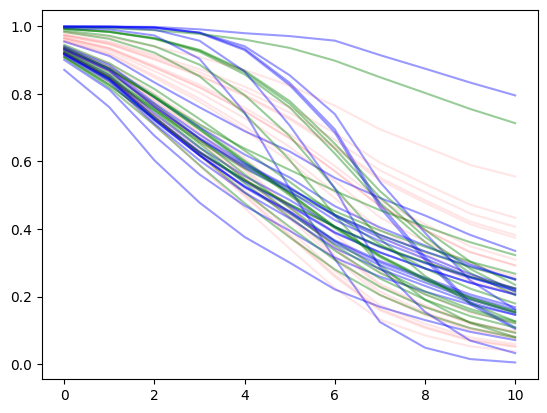

mean shape 2.228082894659091
mean scale 90.91648328181819
503.0
mean time draws 84.6077347422442
cens mean 224.03113636363636
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
800
0.44525


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 176 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 0 0 0 1 0 1 1 1 0 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 0 1 0 0 1 1 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 27202, 11, 44000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.911000
xp1,xp[np*p]: 5.000000, 0.911000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.39456
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

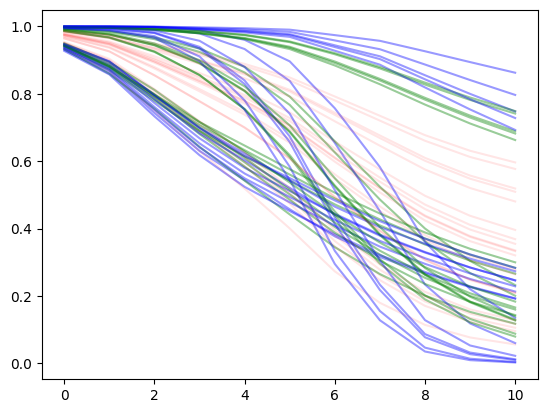

mean shape 2.2634821970227272
mean scale 91.80510150454545
510.0
mean time draws 85.38862870377066
cens mean 236.8084090909091
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
900
0.4435


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 171 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 0 0 1 0 1 0 1 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0 1 0 1 0 1 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 27139, 11, 44000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.695000
xp1,xp[np*p]: 5.000000, 0.695000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.3916
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1

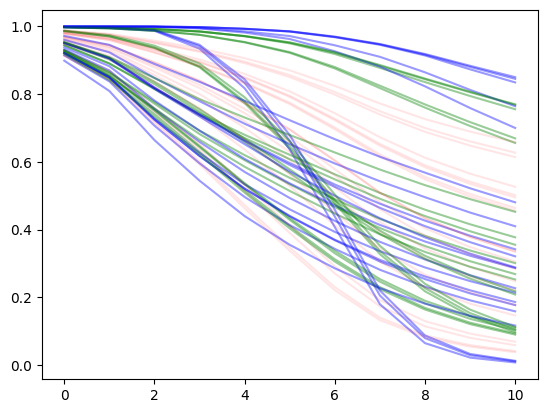

mean shape 2.2681514976136365
mean scale 90.46279278636362
503.0
mean time draws 84.20936651313048
cens mean 230.9131818181818
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
match size
1000
0.43575


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 200 tune and 200 draw iterations (2_400 + 2_400 draws total) took 161 seconds.
Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:4000, 1:10] 1 1 0 0 1 0 0 1 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 1 1 0 1 1 1 1 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 26962, 11, 44000
y1,yn: 0.000000, 0.000000
x1,x[n*p]: 5.000000, 0.480000
xp1,xp[np*p]: 5.000000, 0.480000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.38054
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

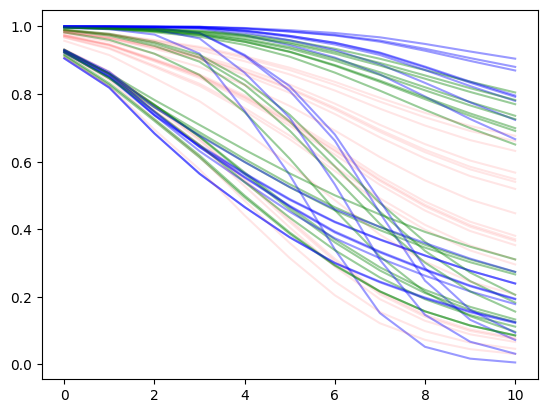

In [177]:
df_trn = pd.DataFrame()
df_tst = pd.DataFrame()
for i in [1,2,3,4,5,6,7,8,9,10]:
# for i in [1]:
    trn_df, tst_df = big_loop(seed = i, N=4000)
    df_trn = pd.concat([trn_df, df_trn])
    df_tst = pd.concat([tst_df, df_tst])

df_trn.to_csv("complex1_N_4000_trn.csv")
df_tst.to_csv("complex1_N_4000_tst.csv")

In [196]:
trn_df
tst_df

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n
0,0.007871,0.007850,0.028812,0.003934,0.001506,0.003054,0.003633,0.002297,0.022580,0.951210,0.951471,0.346265,1.00,1000.0,4000.0
1,0.017464,0.014465,0.055550,0.011656,0.002558,0.007572,0.007386,0.004123,0.045519,0.935983,0.956080,0.352279,0.90,1000.0,4000.0
2,0.036558,0.021531,0.099930,0.002824,-0.003064,0.005124,0.030116,0.004521,0.081655,0.916904,0.971177,0.379133,0.80,1000.0,4000.0
3,0.051222,0.028104,0.128606,-0.001561,-0.009680,0.002118,0.049292,0.008537,0.115123,0.908449,0.972440,0.422863,0.70,1000.0,4000.0
4,0.056189,0.036933,0.137619,0.001777,-0.006704,0.007094,0.037844,0.022036,0.116258,0.917703,0.964444,0.506326,0.60,1000.0,4000.0
5,0.061360,0.041297,0.140088,-0.001166,-0.010713,0.004993,0.042312,0.022971,0.118300,0.920662,0.964063,0.586466,0.50,1000.0,4000.0
6,0.081005,0.048029,0.158696,-0.007369,-0.015291,0.000842,0.058692,0.024875,0.156237,0.893830,0.962676,0.592519,0.40,1000.0,4000.0
7,0.098477,0.047682,0.185966,-0.012628,-0.012478,0.001312,0.069050,0.027451,0.172974,0.876720,0.971098,0.560367,0.30,1000.0,4000.0
8,0.102817,0.045550,0.203312,-0.012274,-0.008435,0.001528,0.077288,0.025973,0.170840,0.882109,0.976862,0.539023,0.20,1000.0,4000.0
9,0.097919,0.040603,0.206441,-0.009062,-0.008088,0.002165,0.081082,0.022757,0.170703,0.895784,0.982081,0.536773,0.10,1000.0,4000.0


In [282]:
n400 = pd.read_csv("complex1_N_400_tst.csv")
n1000 = pd.read_csv("complex1_N_1000_tst.csv")
n4000 = pd.read_csv("complex1_N_4000_tst.csv")

In [314]:
cols = ["p_rmse", "r_rmse", "c_rmse","p_bias", "r_bias", "c_bias", "deciles"]
m400 = pd.DataFrame(n400[cols].groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]]).T
m1000 = pd.DataFrame(n1000[cols].groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]]).T
m4000 = pd.DataFrame(n4000[cols].groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]]).T

pd.concat([m400,m1000, m4000]).to_excel("complex_res_mean.xlsx")

In [292]:
# n400["deciles"] = 1 - n400["deciles"]
# n1000["deciles"] = 1 - n1000["deciles"]
# n4000["deciles"] = 1 - n4000["deciles"]
# n4000["deciles"]
n400["idx"] = n400["Unnamed: 0"]
n400

,Unnamed: 0,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n,idx
0,0,0.018795,0.021747,0.029052,0.001325,-0.001099,-0.004751,0.011303,0.008352,0.022754,0.736123,0.646712,0.369482,1.00,1000.0,400.0,0
1,1,0.035659,0.040633,0.057845,0.004658,-0.003976,-0.017414,0.023447,0.015616,0.041770,0.745397,0.669415,0.330011,0.90,1000.0,400.0,1
2,2,0.058206,0.062411,0.099105,-0.000155,-0.003644,-0.017222,0.039542,0.030821,0.078057,0.797468,0.767147,0.412842,0.80,1000.0,400.0,2
3,3,0.070011,0.070818,0.123763,0.012655,0.010684,-0.002114,0.051163,0.039094,0.097155,0.833974,0.830125,0.481170,0.70,1000.0,400.0,3
4,4,0.075342,0.078886,0.134771,0.018467,0.013979,-0.003785,0.048996,0.039513,0.102698,0.853837,0.839761,0.532311,0.60,1000.0,400.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,6,0.096868,0.105022,0.188502,-0.026746,-0.029476,-0.044972,0.061018,0.059873,0.155574,0.855141,0.829727,0.451449,0.40,100.0,400.0,6
106,7,0.106514,0.109719,0.207902,-0.030900,-0.033740,-0.037491,0.068091,0.067860,0.185458,0.861371,0.852901,0.471843,0.30,100.0,400.0,7
107,8,0.110545,0.108923,0.224766,-0.037712,-0.042846,-0.041401,0.072964,0.068917,0.202278,0.868491,0.872323,0.456327,0.20,100.0,400.0,8
108,9,0.107431,0.106106,0.234244,-0.038934,-0.047688,-0.058521,0.075374,0.068757,0.199053,0.879008,0.881973,0.424779,0.10,100.0,400.0,9


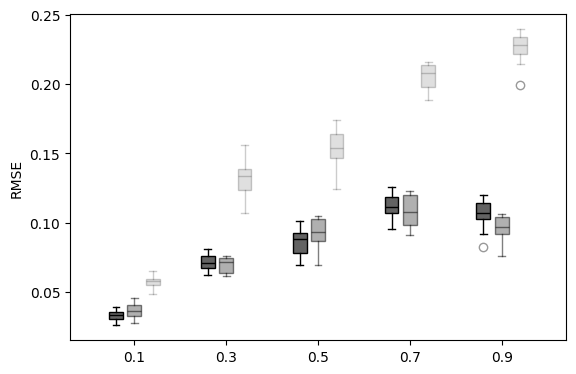

In [304]:
for i in [.9, .7, .5, .3, .1]:
# for i in [1,3,5,7,9]:
    tmp = n400[n400["deciles"]== i]
    # tmp = n400[n400["idx"]== i]
# plt.boxplot(tmp)
    tmp_rmse = tmp[["p_rmse", "r_rmse", "c_rmse"]]
    # plt.boxplot(tmp_rmse)
    pst = (1-i) * 5
    alpha3 = 0.4
    alpha2=1
    plt.boxplot(
            tmp["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    plt.boxplot(
            tmp["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    plt.boxplot(
            tmp["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # lbls = [str(i) for i in [0.1,.2, .3, .4, .5, .6,.7,.8, .9]]
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
# pts = np.array([0.9, .7,  .5, .3, .1]) * 5
pts = np.array([0.1, .3,  .5, .7, .9]) * 5
# pts = np.array([1, 3,  5, 7, 9]) * 5
# lbls = lbls[::-1]
plt.xticks(
    pts, lbls
    # np.hstack([pts-.2, pts, pts + .2]) ,
    # labels =  ["" + x for x in lbls] + ["R" + x for x in lbls]  + ["C" + x for x in lbls] ,
    # labels = ["p-BART " + x for x in lbls] + ["r-BART " + x for x in lbls] + ["CPHM " + x for x in lbls],
    # rotation = 90
)
plt.ylabel("RMSE")
plt.subplots_adjust(bottom=0.20)
plt.savefig("ooo_rmse_N_400.png")

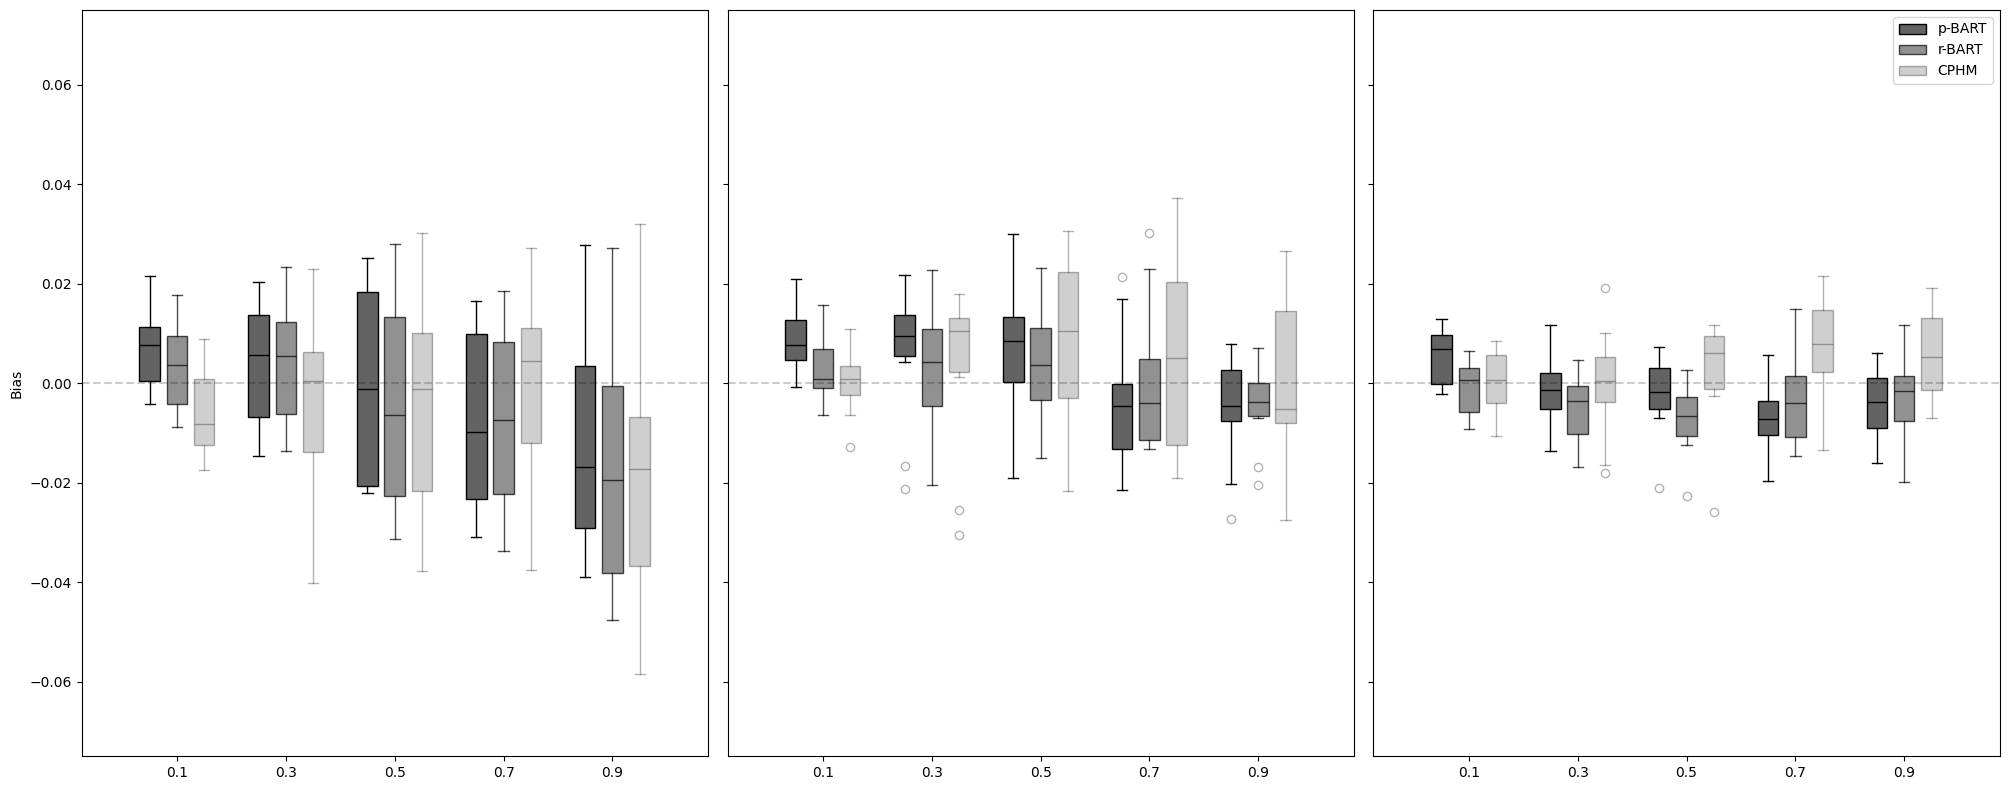

In [305]:
fig,ax = plt.subplots(nrows=1,ncols=3, figsize=(20,8), sharey=True)
scale = 4
for i in [.9, .7, .5, .3, .1]:
    tmp1 = n400[n400["deciles"]== i]
    tmp2 = n1000[n1000["deciles"]== i]
    tmp3 = n4000[n4000["deciles"]== i]

    
    pst = (1-i) * scale
    alpha3 = 0.3
    alpha2=1
    ax[0].boxplot(
            tmp1["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.7
    ax[0].boxplot(
            tmp1["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.3
    ax[0].boxplot(
            tmp1["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # 1000
    alpha2=1
    ax[1].boxplot(
            tmp2["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.7
    ax[1].boxplot(
            tmp2["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.3
    ax[1].boxplot(
            tmp2["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    # 4000
    alpha2=1
    ax[2].boxplot(
            tmp3["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label='p-BART'if i == 0.1 else None
            )
    alpha2=0.7
    ax[2].boxplot(
            tmp3["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="r-BART" if i == 0.1 else None
            )
    alpha2=0.3
    ax[2].boxplot(
            tmp3["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="CPHM" if i == 0.1 else None
            )

lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
pts = np.array([0.1, .3,  .5, .7, .9]) * scale
ax[0].set_xticks(
    pts, lbls
)

ax[1].set_xticks(
    pts,lbls
    
)

ax[2].set_xticks(
    pts,lbls
)
# ax[0].set_ylabel("Bias")
ax[0].set_ylim((-0.075, 0.075))
ax[1].set_ylim((-0.075, 0.075))
ax[2].set_ylim((-0.075, 0.075))
ax[0].axhline(0, linestyle = "--", c="black", alpha=0.2 )
ax[1].axhline(0, linestyle = "--", c="black", alpha=0.2 )
ax[2].axhline(0, linestyle = "--", c="black", alpha=0.2 )
plt.legend()

# ax[0].subplots_adjust(bottom=0.20)
# ax[1].subplots_adjust(bottom=0.20)
# ax[2].subplots_adjust(bottom=0.20)
plt.subplots_adjust(bottom=0.2)
# plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
ax[0].set_ylabel("Bias")
# plt.yticks([0, .05, 0.1, 0.15, 0.2])
# ax[1].set_ylabel()
plt.savefig("2_ooo_bias_comb.png")

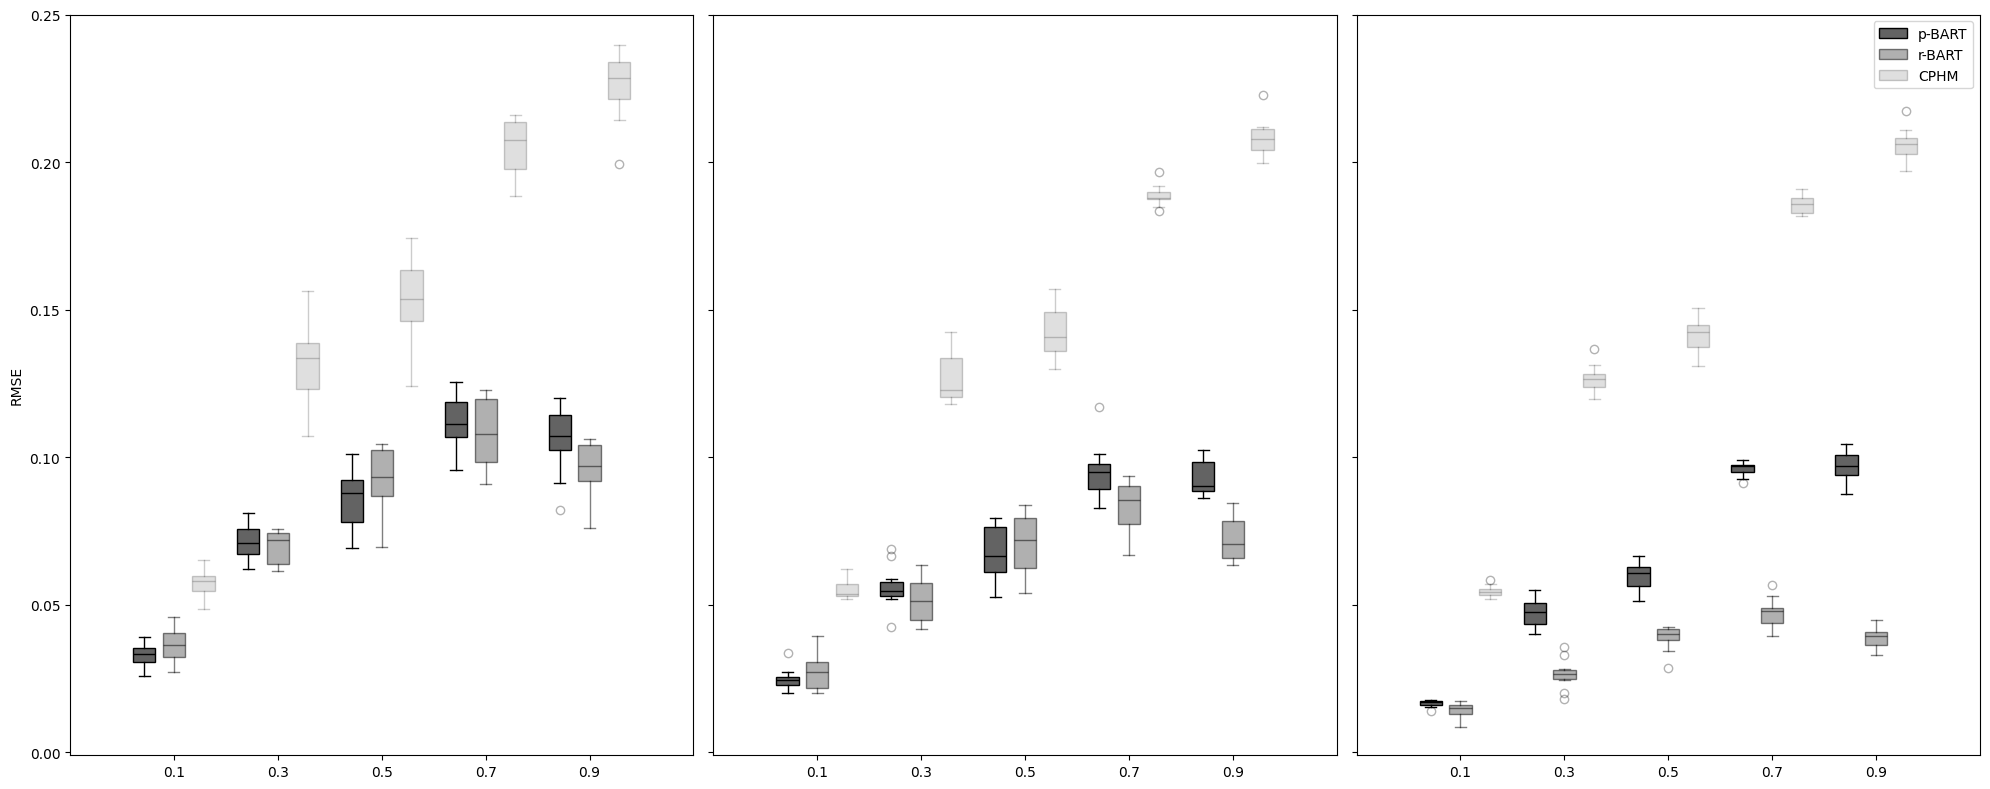

In [306]:
fig,ax = plt.subplots(nrows=1,ncols=3, figsize=(20,8), sharey=True)
scale = 3.5
# for i in [.9, .7]:#,# .5, .3, .1]:
for i in [.1, .3, .5, .7, .9]:
    tmp1 = n400[n400["deciles"]== i]
    tmp2 = n1000[n1000["deciles"]== i]
    tmp3 = n4000[n4000["deciles"]== i]

    
    pst = (1-i) * scale
    alpha3 = 0.3
    alpha2=1
    ax[0].boxplot(
            tmp1["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    ax[0].boxplot(
            tmp1["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    ax[0].boxplot(
            tmp1["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # 1000
    alpha2=1
    ax[1].boxplot(
            tmp2["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    ax[1].boxplot(
            tmp2["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    ax[1].boxplot(
            tmp2["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    # 4000
    alpha2=1
    ax[2].boxplot(
            tmp3["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="p-BART" if i == 0.1 else None
            )
    alpha2=0.5
    ax[2].boxplot(
            tmp3["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="r-BART" if i == 0.1 else None
            )
    alpha2=0.2
    ax[2].boxplot(
            tmp3["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="CPHM" if i == 0.1 else None
            )
    
    
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]

pts = np.array([0.1, .3,  .5, .7, .9]) * scale

ax[0].set_xticks(
    pts,lbls
)

ax[1].set_xticks(
    pts,lbls
)

ax[2].set_xticks(
    pts, lbls
)
# ax[0].set_ylabel("RMSE")
ax[0].set_ylim((-0.001, 0.25))
ax[1].set_ylim((-0.001, 0.25))
ax[2].set_ylim((-0.001, 0.25))
# ax[0].axhline(0, linestyle = "--", c="black", alpha=0.2 )
# ax[1].axhline(0, linestyle = "--", c="black", alpha=0.2 )
# ax[2].axhline(0, linestyle = "--", c="black", alpha=0.2 )
plt.legend()

ax[0].set_ylabel("RMSE")
# ax[0].subplots_adjust(bottom=0.20)
# ax[1].subplots_adjust(bottom=0.20)
# ax[2].subplots_adjust(bottom=0.20)
plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
plt.yticks([0, .05, 0.1, 0.15, .2, .25])
# ax[1].set_ylabel()
plt.savefig("2_ooo_rmse_comb.png")